# ReliefGrid: road-aware relief hub planning

Choose exactly **k** hubs to maximize population-weighted coverage within a road-travel threshold. A bridge closure changes the road graph before every method is evaluated. All geography, populations, and road times here are **synthetic**, released under CC0-1.0. This is an illustrative planning model, with no capacities, traffic prediction, or operational deployment claims.

This notebook contains the complete implementation and both scenarios. Run all cells in order; no application server, repository files, credentials, or remote services are needed. Quantum experiments use an **ideal local simulator**, followed by finite-shot sampling. No hardware results or quantum speedup are claimed.

## Setup and reproducibility

Test environment: Python 3.12.14. Install these packages in your notebook environment before running:

```text
python -m pip install pydantic==2.14.3 networkx==3.7 numpy==2.5.4 scipy==1.18.1 qiskit==2.6.2 ipykernel==7.4.0
```

The notebook uses standard IPython display support and inline SVG, so no plotting or map service is required. Benchmark settings are predefined: eight hubs, k=3, 12-minute response threshold; p=1 and p=2, seeds 42 and 7, 24 expectation evaluations and 256 samples per run. Timings depend on the computer. Exact enumeration audits every feasible subset; its results never choose quantum angles.

## Validated contracts and canonical hashes

In [1]:
"""Canonical v1 contracts. Wire names are also Python attribute names.

Qiskit bit j encodes hubIds[j]; its printed bitstring is reversed relative to
hubIds. For hubIds=(a,b,c), printed '101' means a and c are selected.
"""
from __future__ import annotations

import hashlib
import json
from typing import Any, Literal

from pydantic import BaseModel, ConfigDict, Field, model_validator

SCHEMA_VERSION = "1"
MODEL_VERSION = "1"
Solver = Literal["exact", "greedy", "random", "qaoa"]


class Contract(BaseModel):
    model_config = ConfigDict(extra="forbid", frozen=True, allow_inf_nan=False)


class ScenarioProvenance(Contract):
    kind: Literal["synthetic", "open-data"]
    sources: tuple[str, ...] = ()
    license: str
    retrievedAt: str | None = None
    transformationNotes: str


class Node(Contract):
    id: str = Field(min_length=1)
    lon: float = Field(ge=-180, le=180)
    lat: float = Field(ge=-90, le=90)
    name: str | None = None


class Edge(Contract):
    id: str = Field(min_length=1)
    fromNodeId: str
    toNodeId: str
    travelMinutes: float = Field(gt=0)
    bidirectional: bool
    geometry: dict[str, Any] | None = None
    name: str | None = None


class Community(Contract):
    id: str = Field(min_length=1)
    nodeId: str
    population: float = Field(ge=0)
    priorityMultiplier: float = Field(default=1, ge=0)
    name: str | None = None


class Hub(Contract):
    id: str = Field(min_length=1)
    nodeId: str
    name: str | None = None


class Scenario(Contract):
    schemaVersion: Literal["1"] = "1"
    id: str = Field(min_length=1)
    title: str
    description: str | None = None
    crs: Literal["EPSG:4326"] = "EPSG:4326"
    provenance: ScenarioProvenance
    nodes: tuple[Node, ...]
    edges: tuple[Edge, ...]
    communities: tuple[Community, ...]
    candidateHubs: tuple[Hub, ...]

    @model_validator(mode="after")
    def references(self):
        for key in ("nodes", "edges", "communities", "candidateHubs"):
            ids = [item.id for item in getattr(self, key)]
            if len(ids) != len(set(ids)):
                raise ValueError(f"duplicate IDs in {key}")
        nodes = {n.id for n in self.nodes}
        for edge in self.edges:
            if edge.fromNodeId not in nodes or edge.toNodeId not in nodes:
                raise ValueError(f"unknown node on edge {edge.id}")
            if edge.geometry is not None:
                geometry = edge.geometry
                if geometry.get("type") != "LineString" or len(geometry.get("coordinates", [])) < 2:
                    raise ValueError(f"invalid LineString on edge {edge.id}")
                for point in geometry["coordinates"]:
                    if len(point) != 2 or not (-180 <= point[0] <= 180 and -90 <= point[1] <= 90):
                        raise ValueError(f"invalid coordinates on edge {edge.id}")
        for item in (*self.communities, *self.candidateHubs):
            if item.nodeId not in nodes:
                raise ValueError(f"unknown node on {item.id}")
        return self


class QaoaOptions(Contract):
    layers: int = Field(default=1, ge=1, le=3)
    shots: int = Field(default=512, ge=1, le=8192)
    maxEvaluations: int = Field(default=40, ge=1, le=300)
    starts: int = Field(default=1, ge=1, le=4)


class PlanningRequest(Contract):
    scenarioId: str
    scenarioRevision: str
    closedEdgeIds: tuple[str, ...] = ()
    hubCount: int = Field(ge=0, le=100)
    responseTimeMinutes: float = Field(ge=0, le=10000)
    solver: Solver = "greedy"
    seed: int = Field(default=42, ge=0, le=4294967295)
    qaoa: QaoaOptions | None = None


class PreparedProblem(Contract):
    modelVersion: Literal["1"] = "1"
    scenarioRevision: str
    problemHash: str
    hubIds: tuple[str, ...]
    communityIds: tuple[str, ...]
    hubCount: int = Field(ge=0)
    demandWeights: tuple[float, ...]
    populations: tuple[float, ...]
    coverageMatrix: tuple[tuple[bool, ...], ...]
    travelMinutes: tuple[tuple[float | None, ...], ...]
    responseTimeMinutes: float = Field(default=0, ge=0)
    closedEdgeIds: tuple[str, ...] = ()

    @model_validator(mode="after")
    def dimensions(self):
        n, m = len(self.hubIds), len(self.communityIds)
        if self.hubCount > n:
            raise ValueError("hubCount exceeds candidate hubs")
        if len(set(self.hubIds)) != n or len(set(self.communityIds)) != m:
            raise ValueError("prepared IDs must be unique")
        if self.hubIds != tuple(sorted(self.hubIds)) or self.communityIds != tuple(sorted(self.communityIds)):
            raise ValueError("prepared IDs must be canonically sorted")
        if any(len(v) != m for v in (self.demandWeights, self.populations, self.coverageMatrix, self.travelMinutes)):
            raise ValueError("community dimension mismatch")
        if any(len(row) != n for row in (*self.coverageMatrix, *self.travelMinutes)):
            raise ValueError("hub dimension mismatch")
        if any(x < 0 for x in (*self.demandWeights, *self.populations)):
            raise ValueError("weights and populations must be nonnegative")
        if any(t is not None and t < 0 for row in self.travelMinutes for t in row):
            raise ValueError("travel times must be nonnegative or null")
        return self


class Assignment(Contract):
    communityId: str
    hubId: str | None
    travelMinutes: float | None
    covered: bool


class Timing(Contract):
    preprocessMs: float = Field(default=0, ge=0)
    constructionMs: float = Field(default=0, ge=0)
    optimizationMs: float = Field(default=0, ge=0)
    samplingMs: float = Field(default=0, ge=0)
    totalMs: float = Field(default=0, ge=0)


class Provenance(Contract):
    scenarioRevision: str
    modelVersion: str = MODEL_VERSION
    codeRevision: str = "working-tree"
    versions: dict[str, str] = Field(default_factory=dict)
    executionMode: str = "classical"
    seed: int
    parameters: dict[str, Any] = Field(default_factory=dict)


class PlanResult(Contract):
    solver: Solver
    problemHash: str
    runHash: str
    selectedHubIds: tuple[str, ...]
    feasible: bool
    deployedHubCount: int = Field(ge=0)
    coveredPopulation: float = Field(ge=0)
    totalPopulation: float = Field(ge=0)
    weightedCoverage: float = Field(ge=0)
    uncoveredCommunityIds: tuple[str, ...]
    assignments: tuple[Assignment, ...]
    timing: Timing = Field(default_factory=Timing)
    provenance: Provenance
    diagnostics: dict[str, Any] = Field(default_factory=dict)


def canonical_hash(value: Any) -> str:
    if isinstance(value, BaseModel):
        value = value.model_dump(mode="json", exclude_none=True)
    encoded = json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False, allow_nan=False)
    return hashlib.sha256(encoded.encode("utf-8")).hexdigest()


def scenario_revision(scenario: Scenario) -> str:
    return canonical_hash(scenario)


def problem_hash(**payload: Any) -> str:
    payload.setdefault("modelVersion", MODEL_VERSION)
    if "closedEdgeIds" in payload:
        payload["closedEdgeIds"] = sorted(set(payload["closedEdgeIds"]))
    return canonical_hash(payload)


def run_hash(problem: PreparedProblem, request: PlanningRequest, *, parameters: dict | None = None) -> str:
    options = request.qaoa
    if request.solver == "qaoa" and options is None:
        options = QaoaOptions()
    request_hash = canonical_hash({"problemHash": problem.problemHash, "solver": request.solver,
                                   "seed": request.seed, "qaoa": options.model_dump(mode="json") if options else None})
    if parameters is not None:
        return canonical_hash({"requestRunHash": request_hash, "parameters": parameters})
    return request_hash

## Independent overlap-safe evaluator

In [2]:
"""Independent, overlap-safe scoring and deterministic service assignments."""
from __future__ import annotations

from math import fsum
from typing import Iterable



def evaluate_plan(problem: PreparedProblem, selectedHubIds: Iterable[str]) -> dict:
    """Recompute metrics from a deployment, without trusting solver scores.

    Unknown IDs and duplicate deployments make a plan infeasible. Known unique
    hubs are still scored so invalid samples can be inspected without repair.
    Travel times independently establish inclusive-threshold access; prepared
    graph problems have an equivalent coverage matrix.
    """
    supplied = tuple(selectedHubIds)
    selected = tuple(sorted(set(supplied)))
    indices = {hub: index for index, hub in enumerate(problem.hubIds)}
    known = tuple(hub for hub in selected if hub in indices)
    feasible = (len(supplied) == len(selected) == problem.hubCount
                and len(known) == len(selected))
    covered_indices = []
    assignments = []
    uncovered = []
    for i, community in enumerate(problem.communityIds):
        choices = [(problem.travelMinutes[i][indices[hub]], hub) for hub in known
                   if problem.travelMinutes[i][indices[hub]] is not None
                   and problem.travelMinutes[i][indices[hub]] <= problem.responseTimeMinutes]
        if choices:
            minutes, hub = min(choices)
            covered_indices.append(i)
            assignments.append(dict(communityId=community, hubId=hub,
                                    travelMinutes=minutes, covered=True))
        else:
            uncovered.append(community)
            assignments.append(dict(communityId=community, hubId=None,
                                    travelMinutes=None, covered=False))
    return dict(
        selectedHubIds=selected, feasible=feasible, deployedHubCount=len(known),
        coveredPopulation=fsum(problem.populations[i] for i in covered_indices),
        totalPopulation=fsum(problem.populations),
        weightedCoverage=fsum(problem.demandWeights[i] for i in covered_indices),
        uncoveredCommunityIds=tuple(uncovered), assignments=tuple(assignments),
    )

## Embedded synthetic scenarios and directed road engine
Road travel runs from a hub to a community. Closed roads are removed before shortest paths are calculated; unreachable travel is represented by null. Coverage includes the threshold boundary.

In [3]:
SCENARIOS = json.loads('{"riverbend": {"schemaVersion": "1", "id": "riverbend", "title": "Riverbend district", "description": "Choose supply hubs across two riverbanks. The Alder Bridge is the only crossing; Alder Island has no road access.", "crs": "EPSG:4326", "provenance": {"kind": "synthetic", "sources": ["Original ReliefGrid demonstration fixture; generated by generate_fixtures.py"], "license": "CC0-1.0", "transformationNotes": "Fictional geography, roads, populations and travel times. No real emergency data. Travel times are illustrative fixed minutes; no congestion, capacities or flood prediction. Bridge closure removes both directions. Island n39 has no road access. All priority multipliers equal 1; policy weighting is not inferred from geography."}, "nodes": [{"id": "n00", "lon": -79.974, "lat": 43.538}, {"id": "n01", "lon": -79.963, "lat": 43.538}, {"id": "n02", "lon": -79.952, "lat": 43.538}, {"id": "n03", "lon": -79.943, "lat": 43.538}, {"id": "n04", "lon": -79.925, "lat": 43.538}, {"id": "n05", "lon": -79.914, "lat": 43.538}, {"id": "n06", "lon": -79.903, "lat": 43.538}, {"id": "n07", "lon": -79.974, "lat": 43.53}, {"id": "n08", "lon": -79.963, "lat": 43.53}, {"id": "n09", "lon": -79.952, "lat": 43.53}, {"id": "n10", "lon": -79.943, "lat": 43.53}, {"id": "n11", "lon": -79.925, "lat": 43.53}, {"id": "n12", "lon": -79.914, "lat": 43.53}, {"id": "n13", "lon": -79.903, "lat": 43.53}, {"id": "n14", "lon": -79.974, "lat": 43.522}, {"id": "n15", "lon": -79.963, "lat": 43.522}, {"id": "n16", "lon": -79.952, "lat": 43.522}, {"id": "n17", "lon": -79.943, "lat": 43.522}, {"id": "n18", "lon": -79.925, "lat": 43.522}, {"id": "n19", "lon": -79.914, "lat": 43.522}, {"id": "n20", "lon": -79.903, "lat": 43.522}, {"id": "n21", "lon": -79.974, "lat": 43.514}, {"id": "n22", "lon": -79.963, "lat": 43.514}, {"id": "n23", "lon": -79.952, "lat": 43.514}, {"id": "n24", "lon": -79.943, "lat": 43.514}, {"id": "n25", "lon": -79.925, "lat": 43.514}, {"id": "n26", "lon": -79.914, "lat": 43.514}, {"id": "n27", "lon": -79.903, "lat": 43.514}, {"id": "n28", "lon": -79.974, "lat": 43.506}, {"id": "n29", "lon": -79.963, "lat": 43.506}, {"id": "n30", "lon": -79.952, "lat": 43.506}, {"id": "n31", "lon": -79.943, "lat": 43.506}, {"id": "n32", "lon": -79.925, "lat": 43.506}, {"id": "n33", "lon": -79.914, "lat": 43.506}, {"id": "n34", "lon": -79.903, "lat": 43.506}, {"id": "n35", "lon": -79.891, "lat": 43.53}, {"id": "n36", "lon": -79.88, "lat": 43.534}, {"id": "n37", "lon": -79.88, "lat": 43.522}, {"id": "n38", "lon": -79.888, "lat": 43.512}, {"id": "n39", "lon": -79.934, "lat": 43.546}], "edges": [{"id": "road-h-0-0", "fromNodeId": "n00", "toNodeId": "n01", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.538], [-79.963, 43.538]]}}, {"id": "road-h-0-1", "fromNodeId": "n01", "toNodeId": "n02", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.538], [-79.952, 43.538]]}}, {"id": "road-h-0-2", "fromNodeId": "n02", "toNodeId": "n03", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.538], [-79.943, 43.538]]}}, {"id": "road-h-0-4", "fromNodeId": "n04", "toNodeId": "n05", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.538], [-79.914, 43.538]]}}, {"id": "road-h-0-5", "fromNodeId": "n05", "toNodeId": "n06", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.538], [-79.903, 43.538]]}}, {"id": "road-h-1-0", "fromNodeId": "n07", "toNodeId": "n08", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.53], [-79.963, 43.53]]}}, {"id": "road-h-1-1", "fromNodeId": "n08", "toNodeId": "n09", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.53], [-79.952, 43.53]]}}, {"id": "road-h-1-2", "fromNodeId": "n09", "toNodeId": "n10", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.53], [-79.943, 43.53]]}}, {"id": "road-h-1-4", "fromNodeId": "n11", "toNodeId": "n12", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.53], [-79.914, 43.53]]}}, {"id": "road-h-1-5", "fromNodeId": "n12", "toNodeId": "n13", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.53], [-79.903, 43.53]]}}, {"id": "road-h-2-0", "fromNodeId": "n14", "toNodeId": "n15", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.522], [-79.963, 43.522]]}}, {"id": "road-h-2-1", "fromNodeId": "n15", "toNodeId": "n16", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.522], [-79.952, 43.522]]}}, {"id": "road-h-2-2", "fromNodeId": "n16", "toNodeId": "n17", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.522], [-79.943, 43.522]]}}, {"id": "bridge-main", "fromNodeId": "n17", "toNodeId": "n18", "travelMinutes": 3.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.522], [-79.925, 43.522]]}}, {"id": "road-h-2-4", "fromNodeId": "n18", "toNodeId": "n19", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.522], [-79.914, 43.522]]}}, {"id": "road-h-2-5", "fromNodeId": "n19", "toNodeId": "n20", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.522], [-79.903, 43.522]]}}, {"id": "road-h-3-0", "fromNodeId": "n21", "toNodeId": "n22", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.514], [-79.963, 43.514]]}}, {"id": "road-h-3-1", "fromNodeId": "n22", "toNodeId": "n23", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.514], [-79.952, 43.514]]}}, {"id": "road-h-3-2", "fromNodeId": "n23", "toNodeId": "n24", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.514], [-79.943, 43.514]]}}, {"id": "road-h-3-4", "fromNodeId": "n25", "toNodeId": "n26", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.514], [-79.914, 43.514]]}}, {"id": "road-h-3-5", "fromNodeId": "n26", "toNodeId": "n27", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.514], [-79.903, 43.514]]}}, {"id": "road-h-4-0", "fromNodeId": "n28", "toNodeId": "n29", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.506], [-79.963, 43.506]]}}, {"id": "road-h-4-1", "fromNodeId": "n29", "toNodeId": "n30", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.506], [-79.952, 43.506]]}}, {"id": "road-h-4-2", "fromNodeId": "n30", "toNodeId": "n31", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.506], [-79.943, 43.506]]}}, {"id": "road-h-4-4", "fromNodeId": "n32", "toNodeId": "n33", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.506], [-79.914, 43.506]]}}, {"id": "road-h-4-5", "fromNodeId": "n33", "toNodeId": "n34", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.506], [-79.903, 43.506]]}}, {"id": "road-v-0-0", "fromNodeId": "n00", "toNodeId": "n07", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.538], [-79.974, 43.53]]}}, {"id": "road-v-0-1", "fromNodeId": "n01", "toNodeId": "n08", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.538], [-79.963, 43.53]]}}, {"id": "road-v-0-2", "fromNodeId": "n02", "toNodeId": "n09", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.538], [-79.952, 43.53]]}}, {"id": "road-v-0-3", "fromNodeId": "n03", "toNodeId": "n10", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.538], [-79.943, 43.53]]}}, {"id": "road-v-0-4", "fromNodeId": "n04", "toNodeId": "n11", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.538], [-79.925, 43.53]]}}, {"id": "road-v-0-5", "fromNodeId": "n05", "toNodeId": "n12", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.538], [-79.914, 43.53]]}}, {"id": "road-v-0-6", "fromNodeId": "n06", "toNodeId": "n13", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.538], [-79.903, 43.53]]}}, {"id": "road-v-1-0", "fromNodeId": "n07", "toNodeId": "n14", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.53], [-79.974, 43.522]]}}, {"id": "road-v-1-1", "fromNodeId": "n08", "toNodeId": "n15", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.53], [-79.963, 43.522]]}}, {"id": "road-v-1-2", "fromNodeId": "n09", "toNodeId": "n16", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.53], [-79.952, 43.522]]}}, {"id": "road-v-1-3", "fromNodeId": "n10", "toNodeId": "n17", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.53], [-79.943, 43.522]]}}, {"id": "road-v-1-4", "fromNodeId": "n11", "toNodeId": "n18", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.53], [-79.925, 43.522]]}}, {"id": "road-v-1-5", "fromNodeId": "n12", "toNodeId": "n19", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.53], [-79.914, 43.522]]}}, {"id": "road-v-1-6", "fromNodeId": "n13", "toNodeId": "n20", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.53], [-79.903, 43.522]]}}, {"id": "road-v-2-0", "fromNodeId": "n14", "toNodeId": "n21", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.522], [-79.974, 43.514]]}}, {"id": "road-v-2-1", "fromNodeId": "n15", "toNodeId": "n22", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.522], [-79.963, 43.514]]}}, {"id": "road-v-2-2", "fromNodeId": "n16", "toNodeId": "n23", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.522], [-79.952, 43.514]]}}, {"id": "road-v-2-3", "fromNodeId": "n17", "toNodeId": "n24", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.522], [-79.943, 43.514]]}}, {"id": "road-v-2-4", "fromNodeId": "n18", "toNodeId": "n25", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.522], [-79.925, 43.514]]}}, {"id": "road-v-2-5", "fromNodeId": "n19", "toNodeId": "n26", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.522], [-79.914, 43.514]]}}, {"id": "road-v-2-6", "fromNodeId": "n20", "toNodeId": "n27", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.522], [-79.903, 43.514]]}}, {"id": "road-v-3-0", "fromNodeId": "n21", "toNodeId": "n28", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.514], [-79.974, 43.506]]}}, {"id": "road-v-3-1", "fromNodeId": "n22", "toNodeId": "n29", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.514], [-79.963, 43.506]]}}, {"id": "road-v-3-2", "fromNodeId": "n23", "toNodeId": "n30", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.514], [-79.952, 43.506]]}}, {"id": "road-v-3-3", "fromNodeId": "n24", "toNodeId": "n31", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.514], [-79.943, 43.506]]}}, {"id": "road-v-3-4", "fromNodeId": "n25", "toNodeId": "n32", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.514], [-79.925, 43.506]]}}, {"id": "road-v-3-5", "fromNodeId": "n26", "toNodeId": "n33", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.514], [-79.914, 43.506]]}}, {"id": "road-v-3-6", "fromNodeId": "n27", "toNodeId": "n34", "travelMinutes": 3.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.514], [-79.903, 43.506]]}}, {"id": "east-ridge", "fromNodeId": "n13", "toNodeId": "n35", "travelMinutes": 6.0, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.53], [-79.891, 43.53]]}}, {"id": "ridge-oneway", "fromNodeId": "n35", "toNodeId": "n36", "travelMinutes": 3.75, "bidirectional": false, "geometry": {"type": "LineString", "coordinates": [[-79.891, 43.53], [-79.88, 43.534]]}}, {"id": "ridge-descent", "fromNodeId": "n36", "toNodeId": "n37", "travelMinutes": 5.0, "bidirectional": false, "geometry": {"type": "LineString", "coordinates": [[-79.88, 43.534], [-79.88, 43.522]]}}, {"id": "orchard-road", "fromNodeId": "n37", "toNodeId": "n38", "travelMinutes": 4.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.88, 43.522], [-79.888, 43.512]]}}, {"id": "orchard-return", "fromNodeId": "n38", "toNodeId": "n27", "travelMinutes": 6.0, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.888, 43.512], [-79.903, 43.514]]}}], "communities": [{"id": "community-01", "nodeId": "n00", "population": 430, "priorityMultiplier": 1.0, "name": "Cedar Grove"}, {"id": "community-02", "nodeId": "n02", "population": 690, "priorityMultiplier": 1.0, "name": "Northgate"}, {"id": "community-03", "nodeId": "n07", "population": 520, "priorityMultiplier": 1.0, "name": "Mill Quarter"}, {"id": "community-04", "nodeId": "n10", "population": 830, "priorityMultiplier": 1.0, "name": "Old Town"}, {"id": "community-05", "nodeId": "n14", "population": 610, "priorityMultiplier": 1.0, "name": "Westbank"}, {"id": "community-06", "nodeId": "n17", "population": 970, "priorityMultiplier": 1.0, "name": "Bridgeview"}, {"id": "community-07", "nodeId": "n21", "population": 460, "priorityMultiplier": 1.0, "name": "Willow Fields"}, {"id": "community-08", "nodeId": "n29", "population": 780, "priorityMultiplier": 1.0, "name": "South Meadows"}, {"id": "community-09", "nodeId": "n32", "population": 680, "priorityMultiplier": 1.0, "name": "East Gardens"}, {"id": "community-10", "nodeId": "n06", "population": 540, "priorityMultiplier": 1.0, "name": "Pinecrest"}, {"id": "community-11", "nodeId": "n12", "population": 890, "priorityMultiplier": 1.0, "name": "Riverside East"}, {"id": "community-12", "nodeId": "n20", "population": 720, "priorityMultiplier": 1.0, "name": "Harbour End"}, {"id": "community-13", "nodeId": "n34", "population": 560, "priorityMultiplier": 1.0, "name": "Orchard South"}, {"id": "community-14", "nodeId": "n37", "population": 380, "priorityMultiplier": 1.0, "name": "Ridge Hamlet"}, {"id": "community-15", "nodeId": "n39", "population": 140, "priorityMultiplier": 1.0, "name": "Alder Island"}], "candidateHubs": [{"id": "hub-01", "nodeId": "n08", "name": "Cedar depot"}, {"id": "hub-02", "nodeId": "n16", "name": "Civic hall"}, {"id": "hub-03", "nodeId": "n23", "name": "Westbank school"}, {"id": "hub-04", "nodeId": "n30", "name": "South fairgrounds"}, {"id": "hub-05", "nodeId": "n05", "name": "North fire hall"}, {"id": "hub-06", "nodeId": "n18", "name": "East bridge depot"}, {"id": "hub-07", "nodeId": "n26", "name": "Orchard warehouse"}, {"id": "hub-08", "nodeId": "n35", "name": "Ridge station"}]}, "upland": {"schemaVersion": "1", "id": "upland", "title": "Upland supply corridor", "description": "Choose supply hubs across two riverbanks. The Alder Bridge is the only crossing; Alder Island has no road access.", "crs": "EPSG:4326", "provenance": {"kind": "synthetic", "sources": ["Original ReliefGrid demonstration fixture; generated by generate_fixtures.py"], "license": "CC0-1.0", "transformationNotes": "Fictional geography, roads, populations and travel times. No real emergency data. Travel times are illustrative fixed minutes; no congestion, capacities or flood prediction. Bridge closure removes both directions. Island n39 has no road access. All priority multipliers equal 1; policy weighting is not inferred from geography. Upland variation adds a slow northern crossing and ridge demand."}, "nodes": [{"id": "n00", "lon": -79.974, "lat": 43.538}, {"id": "n01", "lon": -79.963, "lat": 43.538}, {"id": "n02", "lon": -79.952, "lat": 43.538}, {"id": "n03", "lon": -79.943, "lat": 43.538}, {"id": "n04", "lon": -79.925, "lat": 43.538}, {"id": "n05", "lon": -79.914, "lat": 43.538}, {"id": "n06", "lon": -79.903, "lat": 43.538}, {"id": "n07", "lon": -79.974, "lat": 43.53}, {"id": "n08", "lon": -79.963, "lat": 43.53}, {"id": "n09", "lon": -79.952, "lat": 43.53}, {"id": "n10", "lon": -79.943, "lat": 43.53}, {"id": "n11", "lon": -79.925, "lat": 43.53}, {"id": "n12", "lon": -79.914, "lat": 43.53}, {"id": "n13", "lon": -79.903, "lat": 43.53}, {"id": "n14", "lon": -79.974, "lat": 43.522}, {"id": "n15", "lon": -79.963, "lat": 43.522}, {"id": "n16", "lon": -79.952, "lat": 43.522}, {"id": "n17", "lon": -79.943, "lat": 43.522}, {"id": "n18", "lon": -79.925, "lat": 43.522}, {"id": "n19", "lon": -79.914, "lat": 43.522}, {"id": "n20", "lon": -79.903, "lat": 43.522}, {"id": "n21", "lon": -79.974, "lat": 43.514}, {"id": "n22", "lon": -79.963, "lat": 43.514}, {"id": "n23", "lon": -79.952, "lat": 43.514}, {"id": "n24", "lon": -79.943, "lat": 43.514}, {"id": "n25", "lon": -79.925, "lat": 43.514}, {"id": "n26", "lon": -79.914, "lat": 43.514}, {"id": "n27", "lon": -79.903, "lat": 43.514}, {"id": "n28", "lon": -79.974, "lat": 43.506}, {"id": "n29", "lon": -79.963, "lat": 43.506}, {"id": "n30", "lon": -79.952, "lat": 43.506}, {"id": "n31", "lon": -79.943, "lat": 43.506}, {"id": "n32", "lon": -79.925, "lat": 43.506}, {"id": "n33", "lon": -79.914, "lat": 43.506}, {"id": "n34", "lon": -79.903, "lat": 43.506}, {"id": "n35", "lon": -79.891, "lat": 43.53}, {"id": "n36", "lon": -79.88, "lat": 43.534}, {"id": "n37", "lon": -79.88, "lat": 43.522}, {"id": "n38", "lon": -79.888, "lat": 43.512}, {"id": "n39", "lon": -79.934, "lat": 43.546}], "edges": [{"id": "road-h-0-0", "fromNodeId": "n00", "toNodeId": "n01", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.538], [-79.963, 43.538]]}}, {"id": "road-h-0-1", "fromNodeId": "n01", "toNodeId": "n02", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.538], [-79.952, 43.538]]}}, {"id": "road-h-0-2", "fromNodeId": "n02", "toNodeId": "n03", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.538], [-79.943, 43.538]]}}, {"id": "road-h-0-4", "fromNodeId": "n04", "toNodeId": "n05", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.538], [-79.914, 43.538]]}}, {"id": "road-h-0-5", "fromNodeId": "n05", "toNodeId": "n06", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.538], [-79.903, 43.538]]}}, {"id": "road-h-1-0", "fromNodeId": "n07", "toNodeId": "n08", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.53], [-79.963, 43.53]]}}, {"id": "road-h-1-1", "fromNodeId": "n08", "toNodeId": "n09", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.53], [-79.952, 43.53]]}}, {"id": "road-h-1-2", "fromNodeId": "n09", "toNodeId": "n10", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.53], [-79.943, 43.53]]}}, {"id": "road-h-1-4", "fromNodeId": "n11", "toNodeId": "n12", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.53], [-79.914, 43.53]]}}, {"id": "road-h-1-5", "fromNodeId": "n12", "toNodeId": "n13", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.53], [-79.903, 43.53]]}}, {"id": "road-h-2-0", "fromNodeId": "n14", "toNodeId": "n15", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.522], [-79.963, 43.522]]}}, {"id": "road-h-2-1", "fromNodeId": "n15", "toNodeId": "n16", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.522], [-79.952, 43.522]]}}, {"id": "road-h-2-2", "fromNodeId": "n16", "toNodeId": "n17", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.522], [-79.943, 43.522]]}}, {"id": "bridge-main", "fromNodeId": "n17", "toNodeId": "n18", "travelMinutes": 3.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.522], [-79.925, 43.522]]}}, {"id": "road-h-2-4", "fromNodeId": "n18", "toNodeId": "n19", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.522], [-79.914, 43.522]]}}, {"id": "road-h-2-5", "fromNodeId": "n19", "toNodeId": "n20", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.522], [-79.903, 43.522]]}}, {"id": "road-h-3-0", "fromNodeId": "n21", "toNodeId": "n22", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.514], [-79.963, 43.514]]}}, {"id": "road-h-3-1", "fromNodeId": "n22", "toNodeId": "n23", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.514], [-79.952, 43.514]]}}, {"id": "road-h-3-2", "fromNodeId": "n23", "toNodeId": "n24", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.514], [-79.943, 43.514]]}}, {"id": "road-h-3-4", "fromNodeId": "n25", "toNodeId": "n26", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.514], [-79.914, 43.514]]}}, {"id": "road-h-3-5", "fromNodeId": "n26", "toNodeId": "n27", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.514], [-79.903, 43.514]]}}, {"id": "road-h-4-0", "fromNodeId": "n28", "toNodeId": "n29", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.506], [-79.963, 43.506]]}}, {"id": "road-h-4-1", "fromNodeId": "n29", "toNodeId": "n30", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.506], [-79.952, 43.506]]}}, {"id": "road-h-4-2", "fromNodeId": "n30", "toNodeId": "n31", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.506], [-79.943, 43.506]]}}, {"id": "road-h-4-4", "fromNodeId": "n32", "toNodeId": "n33", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.506], [-79.914, 43.506]]}}, {"id": "road-h-4-5", "fromNodeId": "n33", "toNodeId": "n34", "travelMinutes": 4.5, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.506], [-79.903, 43.506]]}}, {"id": "road-v-0-0", "fromNodeId": "n00", "toNodeId": "n07", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.538], [-79.974, 43.53]]}}, {"id": "road-v-0-1", "fromNodeId": "n01", "toNodeId": "n08", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.538], [-79.963, 43.53]]}}, {"id": "road-v-0-2", "fromNodeId": "n02", "toNodeId": "n09", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.538], [-79.952, 43.53]]}}, {"id": "road-v-0-3", "fromNodeId": "n03", "toNodeId": "n10", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.538], [-79.943, 43.53]]}}, {"id": "road-v-0-4", "fromNodeId": "n04", "toNodeId": "n11", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.538], [-79.925, 43.53]]}}, {"id": "road-v-0-5", "fromNodeId": "n05", "toNodeId": "n12", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.538], [-79.914, 43.53]]}}, {"id": "road-v-0-6", "fromNodeId": "n06", "toNodeId": "n13", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.538], [-79.903, 43.53]]}}, {"id": "road-v-1-0", "fromNodeId": "n07", "toNodeId": "n14", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.53], [-79.974, 43.522]]}}, {"id": "road-v-1-1", "fromNodeId": "n08", "toNodeId": "n15", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.53], [-79.963, 43.522]]}}, {"id": "road-v-1-2", "fromNodeId": "n09", "toNodeId": "n16", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.53], [-79.952, 43.522]]}}, {"id": "road-v-1-3", "fromNodeId": "n10", "toNodeId": "n17", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.53], [-79.943, 43.522]]}}, {"id": "road-v-1-4", "fromNodeId": "n11", "toNodeId": "n18", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.53], [-79.925, 43.522]]}}, {"id": "road-v-1-5", "fromNodeId": "n12", "toNodeId": "n19", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.53], [-79.914, 43.522]]}}, {"id": "road-v-1-6", "fromNodeId": "n13", "toNodeId": "n20", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.53], [-79.903, 43.522]]}}, {"id": "road-v-2-0", "fromNodeId": "n14", "toNodeId": "n21", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.522], [-79.974, 43.514]]}}, {"id": "road-v-2-1", "fromNodeId": "n15", "toNodeId": "n22", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.522], [-79.963, 43.514]]}}, {"id": "road-v-2-2", "fromNodeId": "n16", "toNodeId": "n23", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.522], [-79.952, 43.514]]}}, {"id": "road-v-2-3", "fromNodeId": "n17", "toNodeId": "n24", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.522], [-79.943, 43.514]]}}, {"id": "road-v-2-4", "fromNodeId": "n18", "toNodeId": "n25", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.522], [-79.925, 43.514]]}}, {"id": "road-v-2-5", "fromNodeId": "n19", "toNodeId": "n26", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.522], [-79.914, 43.514]]}}, {"id": "road-v-2-6", "fromNodeId": "n20", "toNodeId": "n27", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.522], [-79.903, 43.514]]}}, {"id": "road-v-3-0", "fromNodeId": "n21", "toNodeId": "n28", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.974, 43.514], [-79.974, 43.506]]}}, {"id": "road-v-3-1", "fromNodeId": "n22", "toNodeId": "n29", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.963, 43.514], [-79.963, 43.506]]}}, {"id": "road-v-3-2", "fromNodeId": "n23", "toNodeId": "n30", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.952, 43.514], [-79.952, 43.506]]}}, {"id": "road-v-3-3", "fromNodeId": "n24", "toNodeId": "n31", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.514], [-79.943, 43.506]]}}, {"id": "road-v-3-4", "fromNodeId": "n25", "toNodeId": "n32", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.925, 43.514], [-79.925, 43.506]]}}, {"id": "road-v-3-5", "fromNodeId": "n26", "toNodeId": "n33", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.914, 43.514], [-79.914, 43.506]]}}, {"id": "road-v-3-6", "fromNodeId": "n27", "toNodeId": "n34", "travelMinutes": 5.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.514], [-79.903, 43.506]]}}, {"id": "east-ridge", "fromNodeId": "n13", "toNodeId": "n35", "travelMinutes": 6.0, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.903, 43.53], [-79.891, 43.53]]}}, {"id": "ridge-oneway", "fromNodeId": "n35", "toNodeId": "n36", "travelMinutes": 3.75, "bidirectional": false, "geometry": {"type": "LineString", "coordinates": [[-79.891, 43.53], [-79.88, 43.534]]}}, {"id": "ridge-descent", "fromNodeId": "n36", "toNodeId": "n37", "travelMinutes": 5.0, "bidirectional": false, "geometry": {"type": "LineString", "coordinates": [[-79.88, 43.534], [-79.88, 43.522]]}}, {"id": "orchard-road", "fromNodeId": "n37", "toNodeId": "n38", "travelMinutes": 4.25, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.88, 43.522], [-79.888, 43.512]]}}, {"id": "orchard-return", "fromNodeId": "n38", "toNodeId": "n27", "travelMinutes": 6.0, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.888, 43.512], [-79.903, 43.514]]}}, {"id": "bridge-north", "fromNodeId": "n03", "toNodeId": "n04", "travelMinutes": 18.75, "bidirectional": true, "geometry": {"type": "LineString", "coordinates": [[-79.943, 43.538], [-79.925, 43.538]]}}], "communities": [{"id": "community-01", "nodeId": "n00", "population": 430, "priorityMultiplier": 1.0, "name": "Cedar Grove"}, {"id": "community-02", "nodeId": "n02", "population": 690, "priorityMultiplier": 1.0, "name": "Northgate"}, {"id": "community-03", "nodeId": "n07", "population": 520, "priorityMultiplier": 1.0, "name": "Mill Quarter"}, {"id": "community-04", "nodeId": "n10", "population": 830, "priorityMultiplier": 1.0, "name": "Old Town"}, {"id": "community-05", "nodeId": "n14", "population": 610, "priorityMultiplier": 1.0, "name": "Westbank"}, {"id": "community-06", "nodeId": "n17", "population": 970, "priorityMultiplier": 1.0, "name": "Bridgeview"}, {"id": "community-07", "nodeId": "n21", "population": 460, "priorityMultiplier": 1.0, "name": "Willow Fields"}, {"id": "community-08", "nodeId": "n29", "population": 780, "priorityMultiplier": 1.0, "name": "South Meadows"}, {"id": "community-09", "nodeId": "n32", "population": 680, "priorityMultiplier": 1.0, "name": "East Gardens"}, {"id": "community-10", "nodeId": "n06", "population": 540, "priorityMultiplier": 1.0, "name": "Pinecrest"}, {"id": "community-11", "nodeId": "n12", "population": 890, "priorityMultiplier": 1.0, "name": "Riverside East"}, {"id": "community-12", "nodeId": "n20", "population": 720, "priorityMultiplier": 1.0, "name": "Harbour End"}, {"id": "community-13", "nodeId": "n34", "population": 560, "priorityMultiplier": 1.0, "name": "Orchard South"}, {"id": "community-14", "nodeId": "n37", "population": 920, "priorityMultiplier": 1.0, "name": "Ridge Hamlet"}, {"id": "community-15", "nodeId": "n39", "population": 140, "priorityMultiplier": 1.0, "name": "Alder Island"}], "candidateHubs": [{"id": "hub-01", "nodeId": "n08", "name": "Cedar depot"}, {"id": "hub-02", "nodeId": "n16", "name": "Civic hall"}, {"id": "hub-03", "nodeId": "n23", "name": "Westbank school"}, {"id": "hub-04", "nodeId": "n30", "name": "South fairgrounds"}, {"id": "hub-05", "nodeId": "n05", "name": "North fire hall"}, {"id": "hub-06", "nodeId": "n18", "name": "East bridge depot"}, {"id": "hub-07", "nodeId": "n26", "name": "Orchard warehouse"}, {"id": "hub-08", "nodeId": "n35", "name": "Ridge station"}]}}')

def load_scenario(scenario_id: str) -> Scenario:
    if scenario_id not in SCENARIOS:
        raise KeyError(f'Unknown scenario: {scenario_id}')
    return Scenario.model_validate(SCENARIOS[scenario_id])

def list_scenarios() -> list[dict]:
    return [{'id': key, 'title': load_scenario(key).title, 'scenarioRevision': scenario_revision(load_scenario(key))} for key in sorted(SCENARIOS)]

In [4]:
"""Offline scenario loading and directed, closure-aware road preparation.

Road times are minutes from hubs to communities (never the reverse). Parallel
arcs retain the shortest open edge, breaking equal-time ties by stable edge ID.
"""
from __future__ import annotations

import json
from pathlib import Path
from typing import Iterable

import networkx as nx








def build_graph(scenario: Scenario, closed_edge_ids: Iterable[str] = ()) -> nx.DiGraph:
    closed = set(closed_edge_ids)
    unknown = closed - {edge.id for edge in scenario.edges}
    if unknown:
        raise ValueError(f"Unknown closed edge IDs: {', '.join(sorted(unknown))}")
    graph = nx.DiGraph()
    graph.add_nodes_from(sorted(node.id for node in scenario.nodes))
    # Stable insertion makes Dijkstra's equal-distance path choice reproducible.
    for edge in sorted(scenario.edges, key=lambda edge: edge.id):
        if edge.id in closed:
            continue
        pairs = [(edge.fromNodeId, edge.toNodeId)]
        if edge.bidirectional:
            pairs.append((edge.toNodeId, edge.fromNodeId))
        for source, target in pairs:
            previous = graph.get_edge_data(source, target)
            if previous is None or (edge.travelMinutes, edge.id) < (previous["weight"], previous["edgeId"]):
                graph.add_edge(source, target, weight=edge.travelMinutes, edgeId=edge.id)
    return graph


def prepare_problem(scenario: Scenario, request: PlanningRequest) -> PreparedProblem:
    revision = scenario_revision(scenario)
    if request.scenarioId != scenario.id:
        raise ValueError("Request scenarioId does not match the loaded scenario")
    if request.scenarioRevision != revision:
        raise ValueError("Scenario revision changed; reload the scenario before planning")
    hubs = sorted(scenario.candidateHubs, key=lambda hub: hub.id)
    communities = sorted(scenario.communities, key=lambda community: community.id)
    if request.hubCount > len(hubs):
        raise ValueError("hubCount cannot exceed candidate hub count")
    graph = build_graph(scenario, request.closedEdgeIds)
    distances = [nx.single_source_dijkstra_path_length(graph, hub.nodeId, weight="weight") for hub in hubs]
    travel = [[distance.get(community.nodeId) for distance in distances] for community in communities]
    coverage = [[value is not None and value <= request.responseTimeMinutes for value in row] for row in travel]
    payload = dict(
        modelVersion=MODEL_VERSION, scenarioRevision=revision,
        closedEdgeIds=sorted(set(request.closedEdgeIds)),
        hubIds=[hub.id for hub in hubs], communityIds=[community.id for community in communities],
        hubCount=request.hubCount, responseTimeMinutes=request.responseTimeMinutes,
        demandWeights=[community.population * community.priorityMultiplier for community in communities],
        populations=[community.population for community in communities],
        coverageMatrix=coverage, travelMinutes=travel,
    )
    return PreparedProblem(problemHash=problem_hash(**payload), **payload)


def shortest_service_path(scenario: Scenario, closed_edge_ids: Iterable[str],
                          hub_id: str, community_id: str) -> dict | None:
    """Reconstruct actual service geometry, or None for unreachable demand.

    This helper does not apply the response threshold; callers must check the
    returned minutes before describing a community as covered.
    """
    hubs = {hub.id: hub for hub in scenario.candidateHubs}
    communities = {community.id: community for community in scenario.communities}
    if hub_id not in hubs or community_id not in communities:
        raise ValueError("Unknown hub or community ID")
    graph = build_graph(scenario, closed_edge_ids)
    try:
        minutes, nodes = nx.single_source_dijkstra(
            graph, hubs[hub_id].nodeId, communities[community_id].nodeId, weight="weight")
    except nx.NetworkXNoPath:
        return None
    edge_by_id = {edge.id: edge for edge in scenario.edges}
    node_by_id = {node.id: node for node in scenario.nodes}
    edge_ids = [graph[a][b]["edgeId"] for a, b in zip(nodes, nodes[1:])]
    coordinates = []
    for source, edge_id in zip(nodes, edge_ids):
        edge = edge_by_id[edge_id]
        if edge.geometry:
            points = list(edge.geometry["coordinates"])
            if source != edge.fromNodeId:
                points.reverse()
        else:
            a, b = node_by_id[edge.fromNodeId], node_by_id[edge.toNodeId]
            points = [[a.lon, a.lat], [b.lon, b.lat]]
            if source != edge.fromNodeId:
                points.reverse()
        coordinates.extend(points if not coordinates else points[1:])
    if not coordinates:
        node = node_by_id[nodes[0]]
        coordinates = [[node.lon, node.lat]]
    return {"hubId": hub_id, "communityId": community_id, "nodeIds": nodes,
            "edgeIds": edge_ids, "coordinates": coordinates, "travelMinutes": minutes}


get_service_path = shortest_service_path

## Classical methods
Exact enumerates all k-subsets, greedy takes the largest uncovered gain, and random samples uniform k-subsets with replacement. Every returned deployment is scored by the same independent evaluator. Random and quantum runs use equal sample counts; random has no optimization budget.

In [5]:
"""Fixed-cardinality maximum-coverage baselines on one frozen problem."""
from __future__ import annotations

from collections import Counter
from itertools import combinations
from math import comb, fsum
import platform
import random
from time import perf_counter


MAX_EXACT_COMBINATIONS = 100_000


def classical_parameters(request: PlanningRequest, *, max_combinations: int = MAX_EXACT_COMBINATIONS,
                         samples: int | None = None) -> dict:
    """Return the effective parameters used for classical results and queued run IDs."""
    if request.solver == "exact":
        return {"maxCombinations": max_combinations}
    if request.solver == "greedy":
        return {"tieBreak": "hubId"}
    if request.solver == "random":
        if samples is None:
            samples = request.qaoa.shots if request.qaoa else 512
        return {"samples": samples, "distribution": "uniform fixed-k subsets with replacement"}
    raise ValueError(f"Unknown classical solver: {request.solver}")


def _request(problem: PreparedProblem, request: PlanningRequest, solver: str) -> PlanningRequest:
    if (request.scenarioRevision != problem.scenarioRevision
            or request.hubCount != problem.hubCount
            or request.responseTimeMinutes != problem.responseTimeMinutes
            or tuple(sorted(set(request.closedEdgeIds))) != problem.closedEdgeIds):
        raise ValueError("Request does not match the prepared problem")
    return request.model_copy(update={"solver": solver})


def _score(problem: PreparedProblem, indices: tuple[int, ...] | list[int]) -> float:
    return fsum(weight for weight, row in zip(problem.demandWeights, problem.coverageMatrix)
                if any(row[j] for j in indices))


def _result(problem, request, selected, started, diagnostics, *, sampling=False):
    metrics = evaluate_plan(problem, selected)
    elapsed = (perf_counter() - started) * 1000
    return PlanResult(
        solver=request.solver, problemHash=problem.problemHash,
        runHash=run_hash(problem, request, parameters=diagnostics["parameters"]), **metrics,
        timing=Timing(totalMs=elapsed, samplingMs=elapsed if sampling else 0,
                      optimizationMs=0 if sampling else elapsed),
        provenance=Provenance(scenarioRevision=problem.scenarioRevision,
                              modelVersion=problem.modelVersion, seed=request.seed,
                              versions={"python": platform.python_version()},
                              parameters=diagnostics["parameters"]),
        diagnostics=diagnostics,
    )


def solve_exact(problem: PreparedProblem, request: PlanningRequest, *,
                max_combinations: int = MAX_EXACT_COMBINATIONS) -> PlanResult:
    """Enumerate every k-subset, selecting the lexicographically first optimum.

    Count all optima; retain at most 256 tied sets to bound evidence size.
    An over-limit instance raises before enumeration, never a heuristic result.
    """
    started = perf_counter()
    request = _request(problem, request, "exact")
    count = comb(len(problem.hubIds), problem.hubCount)
    if max_combinations < 1 or count > max_combinations:
        raise ValueError(f"Exact enumeration requires {count} combinations; limit is {max_combinations}")
    best_score, best = -1.0, ()
    optimum_count, optimal_sets = 0, []
    for choice in combinations(range(len(problem.hubIds)), problem.hubCount):
        score = _score(problem, choice)
        ids = tuple(problem.hubIds[j] for j in choice)
        if score > best_score:
            best_score, best = score, ids
            optimum_count, optimal_sets = 1, [ids]
        elif score == best_score:
            optimum_count += 1
            if len(optimal_sets) < 256:
                optimal_sets.append(ids)
    return _result(problem, request, best, started, {
        "evaluations": count, "combinationCount": count, "provenOptimal": True,
        "optimalWeightedCoverage": best_score, "optimumCount": optimum_count,
        "optimalHubSets": optimal_sets, "tieSetsTruncated": optimum_count > len(optimal_sets),
        "parameters": classical_parameters(request, max_combinations=max_combinations),
    })


def solve_greedy(problem: PreparedProblem, request: PlanningRequest) -> PlanResult:
    """Choose greatest uncovered weighted gain, breaking ties by stable hub ID."""
    started = perf_counter()
    request = _request(problem, request, "greedy")
    selected, covered, steps = [], set(), []
    evaluations = 0
    for _ in range(problem.hubCount):
        gains = []
        for j in range(len(problem.hubIds)):
            if j not in selected:
                gain = fsum(weight for i, (weight, row) in enumerate(
                    zip(problem.demandWeights, problem.coverageMatrix)) if i not in covered and row[j])
                gains.append((gain, j))
                evaluations += 1
        gain, chosen = min(gains, key=lambda item: (-item[0], problem.hubIds[item[1]]))
        selected.append(chosen)
        covered.update(i for i, row in enumerate(problem.coverageMatrix) if row[chosen])
        steps.append({"hubId": problem.hubIds[chosen], "marginalWeightedCoverage": gain})
    return _result(problem, request, [problem.hubIds[j] for j in selected], started, {
        "evaluations": evaluations, "provenOptimal": problem.hubCount in (0, len(problem.hubIds)),
        "steps": steps, "parameters": classical_parameters(request),
    })


def solve_random(problem: PreparedProblem, request: PlanningRequest, *, samples: int | None = None) -> PlanResult:
    """Sample uniform k-subsets with replacement and recommend the best sample."""
    started = perf_counter()
    request = _request(problem, request, "random")
    parameters = classical_parameters(request, samples=samples)
    samples = parameters["samples"]
    if isinstance(samples, bool) or not isinstance(samples, int) or not 1 <= samples <= 100_000:
        raise ValueError("samples must be an integer from 1 through 100000")
    rng = random.Random(request.seed)
    counts = Counter(tuple(sorted(rng.sample(range(len(problem.hubIds)), problem.hubCount)))
                     for _ in range(samples))
    scores = {choice: _score(problem, choice) for choice in counts}
    best = min(counts, key=lambda choice: (-scores[choice], choice))
    # Printed bitstrings follow the canonical Qiskit convention: hub index 0 is rightmost.
    bit_counts = {"".join("1" if j in choice else "0" for j in reversed(range(len(problem.hubIds)))): count
                  for choice, count in sorted(counts.items())}
    expected = fsum(scores[choice] * count / samples for choice, count in counts.items())
    return _result(problem, request, [problem.hubIds[j] for j in best], started, {
        "evaluations": len(counts), "sampleCount": samples, "counts": bit_counts,
        "feasibleFraction": 1.0, "expectedWeightedCoverage": expected,
        "bestSampleWeightedCoverage": scores[best], "provenOptimal": False,
        "parameters": parameters,
    }, sampling=True)

## Quantum mechanism

For community i with weight wᵢ and covering hubs Nᵢ, coverage is Σᵢ wᵢ[1−∏ⱼ∈Nᵢ(1−xⱼ)]. The phase compiler applies a controlled phase to the all-zero neighborhood, implementing H = −coverage / Σw up to a global phase. It does not load an enumerated objective oracle.

Preparation excites the first k qubits and applies two fixed XY ring sweeps at π/7 and π/11. Cost phases preserve the basis support; ordered XY mixer gates preserve Hamming weight. Hub j is qubit j, the **rightmost** printed bit. Bounded Powell optimization maximizes expected coverage; recommendation selects the best feasible finite-shot sample. The expected score and best-sample score are different quantities. The post-training exact audit supplies approximation ratios and optimum probabilities only.

In [6]:
"""Exact coverage phases and fixed-weight QAOA on an ideal Qiskit simulator.

Hub j is qubit j (the rightmost printed bit is hubIds[0]). No diagonal
objective oracle is constructed. Cost gates depend only on covering hub sets.
"""
from __future__ import annotations

from collections import Counter
from importlib.metadata import version
from itertools import combinations
from math import comb, pi
from time import perf_counter

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import XXPlusYYGate
from qiskit.quantum_info import DensityMatrix, Statevector
from scipy.optimize import minimize


MAX_QUBITS = 12
MAX_DENSITY_QUBITS = 8
COMPILATION_BASIS = ["rz", "sx", "x", "cx"]


def _validate(problem: PreparedProblem, density: bool = False) -> int:
    n = len(problem.hubIds)
    cap = MAX_DENSITY_QUBITS if density else MAX_QUBITS
    if n > cap:
        raise ValueError(f"QAOA {'density-matrix' if density else 'statevector'} limit is {cap} hubs")
    return n


def coverage_terms(problem: PreparedProblem) -> tuple[tuple[tuple[int, ...], float], ...]:
    """Combine equal neighborhoods without truncating any coverage relation."""
    terms: Counter = Counter()
    for row, weight in zip(problem.coverageMatrix, problem.demandWeights):
        neighbors = tuple(j for j, covered in enumerate(row) if covered)
        if neighbors and weight:
            terms[neighbors] += weight
    return tuple(sorted(terms.items()))


def ring_edges(n: int) -> tuple[tuple[int, int], ...]:
    """Even path edges, odd path edges, then wrap; deduplicated for n <= 2."""
    edges = [(j, j + 1) for parity in (0, 1) for j in range(parity, n - 1, 2)]
    if n > 2:
        edges.append((n - 1, 0))
    return tuple(edges)


def build_preparation(problem: PreparedProblem) -> QuantumCircuit:
    """Publishable fixed recipe: |1^k 0^(n-k)> and two XY ring sweeps.

    Sweep angles pi/7 and pi/11 are fixed independently of problem weights,
    optimum and training seed. Both sweeps follow ring_edges ordering.
    """
    n = _validate(problem)
    circuit = QuantumCircuit(n, name="coherent_feasible_preparation")
    for j in range(problem.hubCount):
        circuit.x(j)
    for angle in (pi / 7, pi / 11):
        for a, b in ring_edges(n):
            circuit.append(XXPlusYYGate(2 * angle), [a, b])
    return circuit


def build_cost_circuit(problem: PreparedProblem, gamma: float) -> QuantumCircuit:
    """U=exp(-i gamma H_C), up to a basis-independent global phase.

    H_C=-coverage/W. An uncovered neighborhood receives exp(-i gamma w/W).
    Thus U_x / U_0 = exp(+i gamma coverage(x)/W), fixing the sign.
    """
    n = _validate(problem)
    circuit = QuantumCircuit(n, name="coverage_phase")
    total = sum(problem.demandWeights)
    if total == 0:
        return circuit
    for neighbors, weight in coverage_terms(problem):
        for j in neighbors:
            circuit.x(j)
        angle = -float(gamma) * weight / total
        if len(neighbors) == 1:
            circuit.p(angle, neighbors[0])
        else:
            circuit.mcp(angle, list(neighbors[:-1]), neighbors[-1])
        for j in neighbors:
            circuit.x(j)
    return circuit


def build_mixer(problem: PreparedProblem, beta: float) -> QuantumCircuit:
    circuit = QuantumCircuit(len(problem.hubIds), name="ordered_XY_ring")
    for a, b in ring_edges(len(problem.hubIds)):
        circuit.append(XXPlusYYGate(2 * float(beta)), [a, b])
    return circuit


def build_qaoa_circuit(problem: PreparedProblem, gammas, betas) -> QuantumCircuit:
    if len(gammas) != len(betas) or not 1 <= len(gammas) <= 3:
        raise ValueError("provide matching gamma/beta arrays of length 1..3")
    circuit = build_preparation(problem)
    for gamma, beta in zip(gammas, betas):
        circuit.compose(build_cost_circuit(problem, gamma), inplace=True)
        circuit.compose(build_mixer(problem, beta), inplace=True)
    return circuit


def qaoa_probabilities(problem: PreparedProblem, gammas, betas, *, dephase_after_cost=False) -> np.ndarray:
    """Complete basis dephasing after every cost, bounded to eight hubs."""
    _validate(problem, density=dephase_after_cost)
    if not dephase_after_cost:
        return Statevector.from_instruction(build_qaoa_circuit(problem, gammas, betas)).probabilities()
    if len(gammas) != len(betas) or not 1 <= len(gammas) <= 3:
        raise ValueError("provide matching gamma/beta arrays of length 1..3")
    state = DensityMatrix(Statevector.from_instruction(build_preparation(problem)))
    for gamma, beta in zip(gammas, betas):
        state = state.evolve(build_cost_circuit(problem, gamma))
        state = DensityMatrix(np.diag(np.diag(state.data)))
        state = state.evolve(build_mixer(problem, beta))
    return state.probabilities()


def expected_coverage(problem: PreparedProblem, probabilities) -> float:
    """Sum neighborhood coverage probabilities; this is not a gate oracle."""
    indices = np.arange(len(probabilities), dtype=np.uint64)
    value = 0.0
    for neighbors, weight in coverage_terms(problem):
        mask = sum(1 << j for j in neighbors)
        value += weight * float(np.sum(np.asarray(probabilities)[(indices & mask) != 0]))
    return value


def bitstring_hubs(problem: PreparedProblem, bitstring: str) -> tuple[str, ...]:
    if len(bitstring) != len(problem.hubIds) or set(bitstring) - {"0", "1"}:
        raise ValueError("bitstring must have exactly one binary digit per hub")
    return tuple(hub for j, hub in enumerate(problem.hubIds) if bitstring[-1 - j] == "1")


def run_ablations(problem: PreparedProblem, gammas, betas) -> dict:
    """Same angles/preparation/mixer; remove phases or remove coherence."""
    coherent = qaoa_probabilities(problem, gammas, betas)
    zero = qaoa_probabilities(problem, np.zeros(len(gammas)), betas)
    dephased = qaoa_probabilities(problem, gammas, betas, dephase_after_cost=True)
    return {
        "gammas": list(gammas), "betas": list(betas),
        "coherent": {"expectedWeightedCoverage": expected_coverage(problem, coherent), "probabilities": coherent.tolist()},
        "gammaZero": {"expectedWeightedCoverage": expected_coverage(problem, zero), "probabilities": zero.tolist()},
        "dephased": {"expectedWeightedCoverage": expected_coverage(problem, dephased), "probabilities": dephased.tolist()},
        "coherentGammaZeroTotalVariation": float(np.abs(coherent - zero).sum() / 2),
        "coherentDephasedTotalVariation": float(np.abs(coherent - dephased).sum() / 2),
    }


def solve_qaoa(problem: PreparedProblem, request: PlanningRequest) -> PlanResult:
    start = perf_counter()
    n = _validate(problem)
    if (request.hubCount != problem.hubCount or request.scenarioRevision != problem.scenarioRevision
            or request.responseTimeMinutes != problem.responseTimeMinutes
            or tuple(sorted(set(request.closedEdgeIds))) != problem.closedEdgeIds):
        raise ValueError("request does not match prepared problem")
    options = request.qaoa or QaoaOptions()
    request = request.model_copy(update={"solver": "qaoa", "qaoa": options})
    rng = np.random.default_rng(request.seed)
    sample_seed = int(rng.integers(0, 2**32))
    construction_start = perf_counter()
    preparation = build_preparation(problem)
    p = options.layers
    convergence, start_records = [], []
    best_value, best_angles = -1.0, np.zeros(2 * p)
    construction_ms = (perf_counter() - construction_start) * 1000
    optimization_start = perf_counter()
    trivial = problem.hubCount in (0, n) or sum(problem.demandWeights) == 0
    # maxEvaluations is a total circuit expectation budget, split across starts.
    starts = min(options.starts, options.maxEvaluations)
    if not trivial:
        for restart in range(starts):
            budget = options.maxEvaluations // starts + (restart < options.maxEvaluations % starts)
            initial = np.concatenate([rng.uniform(-pi, pi, p), rng.uniform(-pi / 2, pi / 2, p)])
            used = 0

            def loss(angles):
                nonlocal used, best_value, best_angles
                used += 1
                probabilities = qaoa_probabilities(problem, angles[:p], angles[p:])
                value = expected_coverage(problem, probabilities)
                if value > best_value:
                    best_value, best_angles = value, np.array(angles)
                convergence.append({"evaluation": len(convergence) + 1, "start": restart,
                                    "expectedWeightedCoverage": value, "bestExpectedWeightedCoverage": best_value})
                return -value / sum(problem.demandWeights)

            fit = minimize(loss, initial, method="Powell", bounds=[(-pi, pi)] * p + [(-pi / 2, pi / 2)] * p,
                           options={"maxfev": int(budget), "xtol": 0.01, "ftol": 0.0001})
            start_records.append({"start": restart, "initialAngles": initial.tolist(), "evaluations": used,
                                  "success": bool(fit.success), "message": str(fit.message)})
    optimization_ms = (perf_counter() - optimization_start) * 1000
    sampling_start = perf_counter()
    if trivial:
        # Explicit deterministic bypass, including the W=0 convention.
        probabilities = np.zeros(2**n)
        probabilities[(1 << problem.hubCount) - 1] = 1
        circuit = QuantumCircuit(n)
        for j in range(problem.hubCount):
            circuit.x(j)
    else:
        circuit = build_qaoa_circuit(problem, best_angles[:p], best_angles[p:])
        probabilities = Statevector.from_instruction(circuit).probabilities()
    probabilities = np.maximum(probabilities, 0)
    probabilities /= probabilities.sum()
    raw = np.random.default_rng(sample_seed).multinomial(options.shots, probabilities)
    counts = {format(i, f"0{n}b") if n else "": int(count) for i, count in enumerate(raw) if count}
    scored = [(bits, count, evaluate_plan(problem, bitstring_hubs(problem, bits))) for bits, count in counts.items()]
    valid = [item for item in scored if item[2]["feasible"]]
    if not valid:
        raise RuntimeError("ideal feasible circuit produced no feasible samples")
    selected = min(valid, key=lambda item: (-item[2]["weightedCoverage"], item[2]["selectedHubIds"]))[2]
    sampling_ms = (perf_counter() - sampling_start) * 1000
    # Independent post-training classical audit, never used to choose angles.
    audit_start = perf_counter()
    optimal_value, optimal_sets = None, []
    if comb(n, problem.hubCount) <= 5000:
        for hubs in combinations(problem.hubIds, problem.hubCount):
            score = evaluate_plan(problem, hubs)["weightedCoverage"]
            if optimal_value is None or score > optimal_value:
                optimal_value, optimal_sets = score, [hubs]
            elif score == optimal_value:
                optimal_sets.append(hubs)
    optimum_indices = [sum(1 << problem.hubIds.index(hub) for hub in hubs) for hubs in optimal_sets]
    audit_ms = (perf_counter() - audit_start) * 1000
    compilation_start = perf_counter()
    compiled = transpile(circuit, basis_gates=COMPILATION_BASIS, optimization_level=1, seed_transpiler=request.seed)
    prep_compiled = transpile(circuit if trivial else preparation, basis_gates=COMPILATION_BASIS, optimization_level=1, seed_transpiler=request.seed)
    compilation_ms = (perf_counter() - compilation_start) * 1000
    construction_ms += compilation_ms
    feasible_mask = [i.bit_count() == problem.hubCount for i in range(2**n)]
    diagnostics = {
        "counts": counts, "shots": options.shots, "samplingSeed": sample_seed,
        "bitOrder": "rightmost bit is hubIds[0]; qubit j is hubIds[j]",
        "expectedWeightedCoverage": expected_coverage(problem, probabilities),
        "sampledExpectedWeightedCoverage": sum(count * metrics["weightedCoverage"] for _, count, metrics in scored) / options.shots,
        "feasibleFraction": sum(count for _, count, metrics in scored if metrics["feasible"]) / options.shots,
        "idealFeasibleProbability": float(probabilities[feasible_mask].sum()),
        "infeasibleCounts": {bits: count for bits, count, metrics in scored if not metrics["feasible"]},
        "idealInfeasibleProbability": float(probabilities[np.logical_not(feasible_mask)].sum()),
        "optimalWeightedCoverage": optimal_value, "optimalHubSets": [list(hubs) for hubs in optimal_sets],
        "optimumProbability": float(probabilities[optimum_indices].sum()) if optimal_value is not None else None,
        "sampledOptimumProbability": sum(count for _, count, metrics in scored if metrics["weightedCoverage"] == optimal_value) / options.shots if optimal_value is not None else None,
        "expectedApproximationRatio": expected_coverage(problem, probabilities) / optimal_value if optimal_value else None,
        "evaluations": len(convergence), "convergence": convergence, "starts": start_records,
        "gammas": best_angles[:p].tolist(), "betas": best_angles[p:].tolist(), "trivialBypass": trivial,
        "resources": {"qubits": n, "layers": p, "depth": compiled.depth(),
                      "twoQubitGates": sum(1 for inst in compiled.data if inst.operation.num_qubits == 2),
                      "operationCounts": dict(compiled.count_ops()), "basisGates": COMPILATION_BASIS,
                      "preparationDepth": prep_compiled.depth(), "preparationTwoQubitGates": sum(1 for inst in prep_compiled.data if inst.operation.num_qubits == 2),
                      "uniqueCoverageNeighborhoods": len(coverage_terms(problem)), "compilationOptimizationLevel": 1},
        "preparationRecipe": "first k qubits excited; ordered ring XY sweeps at pi/7 then pi/11",
        "optimizer": "bounded scipy Powell; total maxfev split across starts",
        "selectionRule": "best feasible finite-shot sample; stable hub-ID ties",
        "audit": "exact feasible enumeration after training; never used by circuit or optimizer",
        "timingBreakdownMs": {"postTrainingExactAudit": audit_ms, "compilation": compilation_ms},
    }
    return PlanResult(solver="qaoa", problemHash=problem.problemHash, runHash=run_hash(problem, request), **selected,
                      timing=Timing(constructionMs=construction_ms, optimizationMs=optimization_ms, samplingMs=sampling_ms,
                                    totalMs=(perf_counter() - start) * 1000),
                      provenance=Provenance(scenarioRevision=problem.scenarioRevision, seed=request.seed,
                          executionMode="ideal-simulator optimization with sampled evaluation",
                          versions={name: version(name) for name in ("qiskit", "numpy", "scipy")},
                          parameters=options.model_dump()), diagnostics=diagnostics)

## Evidence helpers
Tables include losses against the exact optimum. SVG maps use the embedded road geometry and reconstructed shortest service paths; they require no basemap downloads.

In [7]:
from html import escape
from IPython.display import display, HTML, SVG
import platform

def show_table(rows):
    if not rows:
        return
    keys = list(rows[0])
    def fmt(value):
        return f"{value:.3f}" if isinstance(value, float) else str(value)
    display(HTML("<table><thead><tr>" + "".join(f"<th>{escape(k)}</th>" for k in keys) +
                 "</tr></thead><tbody>" + "".join("<tr>" + "".join(f"<td>{escape(fmt(row[k]))}</td>" for k in keys) + "</tr>" for row in rows) + "</tbody></table>"))

def map_svg(scenario, problem, result, title):
    nodes = {n.id: n for n in scenario.nodes}
    xs, ys = [n.lon for n in scenario.nodes], [n.lat for n in scenario.nodes]
    def point(lon, lat):
        return (35 + 730 * (lon-min(xs))/(max(xs)-min(xs)), 380-330*(lat-min(ys))/(max(ys)-min(ys)))
    def line(coords, color, width, extra=""):
        points = " ".join(f"{x:.1f},{y:.1f}" for x,y in [point(*c) for c in coords])
        return f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="{width}" {extra}/>'
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 800 450"><rect width="800" height="450" fill="#f5f4f0"/><text x="20" y="22" font-size="16">{escape(title)}</text>']
    for edge in scenario.edges:
        coords = edge.geometry["coordinates"] if edge.geometry else [[nodes[edge.fromNodeId].lon,nodes[edge.fromNodeId].lat],[nodes[edge.toNodeId].lon,nodes[edge.toNodeId].lat]]
        closed = edge.id in problem.closedEdgeIds
        parts.append(line(coords, "#b9402f" if closed else "#aab5bc", 4 if closed else 1.5, 'stroke-dasharray="5 3"' if closed else ""))
    for assignment in result.assignments:
        if assignment.covered:
            path = shortest_service_path(scenario, problem.closedEdgeIds, assignment.hubId, assignment.communityId)
            parts.append(line(path["coordinates"], "#087f78", 2.5))
    unserved = set(result.uncoveredCommunityIds)
    for community in scenario.communities:
        node = nodes[community.nodeId]; x,y = point(node.lon,node.lat)
        parts.append(f'<circle cx="{x}" cy="{y}" r="4" fill="{ "#8a5a0a" if community.id in unserved else "#172b3a"}"><title>{escape(community.id)}</title></circle>')
    for hub in scenario.candidateHubs:
        node = nodes[hub.nodeId]; x,y = point(node.lon,node.lat); selected = hub.id in result.selectedHubIds
        parts.append(f'<rect x="{x-6}" y="{y-6}" width="12" height="12" fill="{"#087f78" if selected else "white"}" stroke="#172b3a"/><text x="{x+8}" y="{y-8}" font-size="11">{escape(hub.id)}</text>')
    parts.append('<text x="20" y="425" font-size="12">Square: hub (teal = deployed); circle: community (brown = uncovered); dashed red: closed road.</text></svg>')
    display(SVG("".join(parts)))

def request_for(scenario, closures=(), seed=42, layers=1):
    return PlanningRequest(scenarioId=scenario.id, scenarioRevision=scenario_revision(scenario), closedEdgeIds=tuple(closures), hubCount=3, responseTimeMinutes=12, seed=seed,
                           qaoa=QaoaOptions(layers=layers, shots=256, maxEvaluations=24, starts=1))

def result_row(case, result, optimum):
    d = result.diagnostics
    return {"case": case, "method": result.solver, "hubs": ", ".join(result.selectedHubIds), "score": result.weightedCoverage,
            "loss": optimum-result.weightedCoverage, "expected score": d.get("expectedWeightedCoverage", result.weightedCoverage),
            "population": result.coveredPopulation, "feasible": result.feasible, "total ms": result.timing.totalMs}

## Nominal plan and bridge closure
The same request, prepared matrix, and canonical problem hash reach every method. Each deployment uses exactly three hubs. Population and weighted coverage are reported separately, even when fixture weights make them equal.

case,method,hubs,score,loss,expected score,population,feasible,total ms
nominal,exact,"hub-01, hub-07, hub-08",9060.000,0.000,9060.000,9060.000,True,1.030
nominal,greedy,"hub-01, hub-07, hub-08",9060.000,0.000,9060.000,9060.000,True,0.201
nominal,random,"hub-01, hub-07, hub-08",9060.000,0.000,6684.922,9060.000,True,2.505
nominal,qaoa,"hub-01, hub-05, hub-07",8680.000,380.000,6579.552,8680.000,True,993.329
bridge closed,exact,"hub-01, hub-02, hub-07",8140.000,0.000,8140.000,8140.000,True,0.966
bridge closed,greedy,"hub-01, hub-02, hub-07",8140.000,0.000,8140.000,8140.000,True,0.173
bridge closed,random,"hub-01, hub-02, hub-07",8140.000,0.000,6366.289,8140.000,True,2.164
bridge closed,qaoa,"hub-01, hub-03, hub-07",8140.000,0.000,6497.865,8140.000,True,546.443


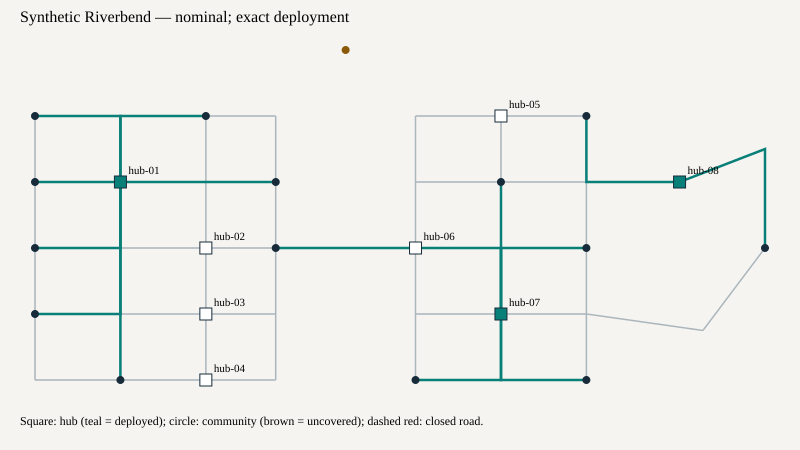

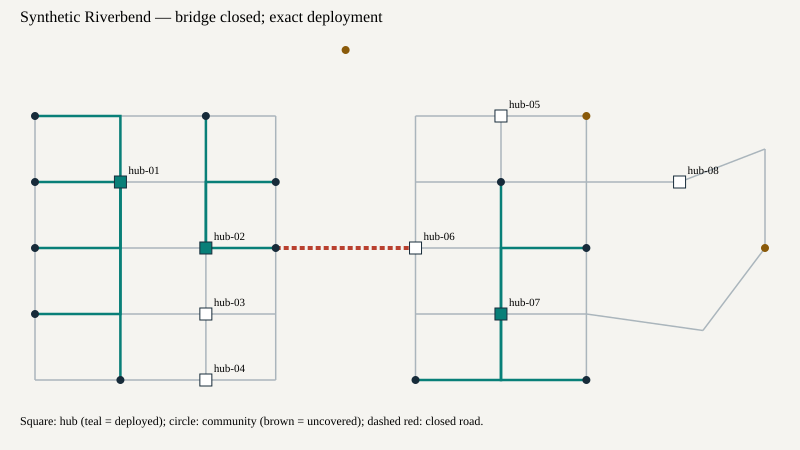

Python 3.12.12
Scenario revision 20f810dc56126ac9242ed9596542d9c8857dc8d00d3a646a71025b83042f1a6e
Problem hashes {'nominal': '05cbc9a7e3967c42498931800735e2a005cf38f7d6e5c36a2a7ca7433df7cd71', 'bridge closed': 'd341db5b2fbbae6b435bd941fa31a47a20768ff97f37141b002b54fa5ee9090d'}


In [8]:
scenario = load_scenario("riverbend")
assert len(scenario.candidateHubs) == 8
bridge = next(edge.id for edge in scenario.edges if "bridge" in (edge.name or "").lower() or "bridge" in edge.id.lower())
cases = {"nominal": (), "bridge closed": (bridge,)}
primary, primary_rows = {}, []
for name, closures in cases.items():
    request = request_for(scenario, closures)
    problem = prepare_problem(scenario, request)
    exact = solve_exact(problem, request)
    results = [exact, solve_greedy(problem, request), solve_random(problem, request), solve_qaoa(problem, request)]
    for result in results:
        assert result.problemHash == problem.problemHash
        assert evaluate_plan(problem, result.selectedHubIds)["weightedCoverage"] == result.weightedCoverage
        assert result.feasible
        primary_rows.append(result_row(name, result, exact.weightedCoverage))
    primary[name] = (problem, results)
show_table(primary_rows)
for name, (problem, results) in primary.items():
    map_svg(scenario, problem, results[0], f"Synthetic Riverbend — {name}; exact deployment")
print("Python", platform.python_version())
print("Scenario revision", scenario_revision(scenario))
print("Problem hashes", {name: problem.problemHash for name,(problem,_) in primary.items()})

## Predefined benchmark and held-out disruptions
Train only on each nominal or bridge-closed instance. Then evaluate the selected deployment without retraining under one additional road closure. These stress evaluations are held out from angle optimization; they are not a robust-optimization algorithm. Seeds and depths are fixed before results are observed. Include all outcomes, even when random or greedy wins.

In [9]:
benchmark_rows, benchmark_runs, stress_rows = [], [], []
heldout = [edge.id for edge in sorted(scenario.edges, key=lambda e:e.id) if edge.id != bridge][:2]
for case, closures in cases.items():
    for layers in (1, 2):
        for seed in (42, 7):
            request = request_for(scenario, closures, seed, layers)
            problem = prepare_problem(scenario, request)
            exact = solve_exact(problem, request)
            quantum = solve_qaoa(problem, request)
            random_result = solve_random(problem, request)
            benchmark_runs.append({"case": case, "request": request.model_dump(mode="json"), "problemHash": problem.problemHash,
                                   "qaoa": quantum.model_dump(mode="json"), "random": random_result.model_dump(mode="json")})
            for result in (quantum, random_result):
                row = result_row(case, result, exact.weightedCoverage)
                row.update({"p": layers, "seed": seed})
                benchmark_rows.append(row)
            for edge in heldout:
                stress_request = request_for(scenario, tuple(sorted(set(closures) | {edge})), seed, layers)
                stress_problem = prepare_problem(scenario, stress_request)
                stress_optimum = solve_exact(stress_problem, stress_request).weightedCoverage
                score = evaluate_plan(stress_problem, quantum.selectedHubIds)["weightedCoverage"]
                stress_rows.append({"trained case": case, "p": layers, "seed": seed, "extra closure": edge,
                                    "fixed deployment score": score, "stress optimum": stress_optimum, "loss": stress_optimum-score})
show_table(benchmark_rows)
show_table(stress_rows)

case,method,hubs,score,loss,expected score,population,feasible,total ms,p,seed
nominal,qaoa,"hub-01, hub-05, hub-07",8680.000,380.000,6579.552,8680.000,True,805.871,1,42
nominal,random,"hub-01, hub-07, hub-08",9060.000,0.000,6684.922,9060.000,True,2.787,1,42
nominal,qaoa,"hub-01, hub-07, hub-08",9060.000,0.000,6620.330,9060.000,True,760.686,1,7
nominal,random,"hub-01, hub-07, hub-08",9060.000,0.000,6722.773,9060.000,True,2.251,1,7
nominal,qaoa,"hub-01, hub-07, hub-08",9060.000,0.000,6650.900,9060.000,True,1445.097,2,42
nominal,random,"hub-01, hub-07, hub-08",9060.000,0.000,6684.922,9060.000,True,1.255,2,42
nominal,qaoa,"hub-01, hub-06, hub-08",8500.000,560.000,6610.156,8500.000,True,438.161,2,7
nominal,random,"hub-01, hub-07, hub-08",9060.000,0.000,6722.773,9060.000,True,0.881,2,7
bridge closed,qaoa,"hub-01, hub-03, hub-07",8140.000,0.000,6497.865,8140.000,True,151.182,1,42
bridge closed,random,"hub-01, hub-02, hub-07",8140.000,0.000,6366.289,8140.000,True,0.649,1,42


trained case,p,seed,extra closure,fixed deployment score,stress optimum,loss
nominal,1,42,east-ridge,8680.000,8680.000,0.000
nominal,1,42,orchard-return,8680.000,9060.000,380.000
nominal,1,7,east-ridge,8520.000,8680.000,160.000
nominal,1,7,orchard-return,9060.000,9060.000,0.000
nominal,2,42,east-ridge,8520.000,8680.000,160.000
nominal,2,42,orchard-return,9060.000,9060.000,0.000
nominal,2,7,east-ridge,7960.000,8680.000,720.000
nominal,2,7,orchard-return,8500.000,9060.000,560.000
bridge closed,1,42,east-ridge,8140.000,8140.000,0.000
bridge closed,1,42,orchard-return,8140.000,8140.000,0.000


## Convergence and compiled resources
Convergence records actual expectation evaluations, including evaluations that worsen the score. Compilation uses rz/sx/x/cx at optimization level 1; gate counts depend on synthesis and installed Qiskit version. Statevector simulation and general controlled phases scale exponentially, so these eight-hub measurements do not establish performance on large networks.

case,p,seed,qubits,depth,2-qubit gates,evaluations,feasible fraction,optimum probability,expected ratio,total ms
nominal,1,42,8,266,166,24,1.000,0.002,0.726,805.871
nominal,1,7,8,213,148,24,1.000,0.002,0.731,760.686
nominal,2,42,8,492,300,24,1.000,0.012,0.734,1445.097
nominal,2,7,8,492,300,24,1.000,0.001,0.730,438.161
bridge closed,1,42,8,124,108,24,1.000,0.020,0.798,151.182
bridge closed,1,7,8,97,92,24,1.000,0.020,0.805,143.547
bridge closed,2,42,8,209,184,24,1.000,0.077,0.780,265.627
bridge closed,2,7,8,209,184,24,1.000,0.013,0.807,563.209


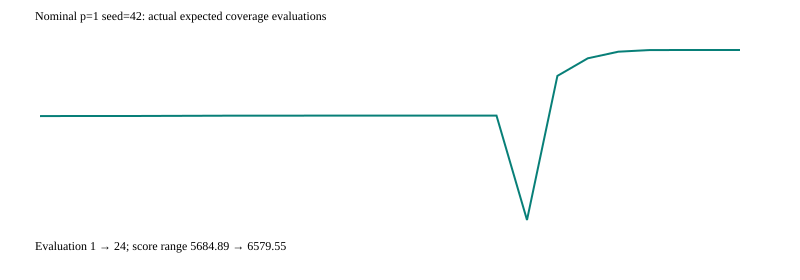

In [10]:
resource_rows = []
for run in benchmark_runs:
    r = run["qaoa"]; d = r["diagnostics"]; resources = d["resources"]
    resource_rows.append({"case": run["case"], "p": resources["layers"], "seed": r["provenance"]["seed"],
                          "qubits": resources["qubits"], "depth": resources["depth"], "2-qubit gates": resources["twoQubitGates"],
                          "evaluations": d["evaluations"], "feasible fraction": d["feasibleFraction"],
                          "optimum probability": d["optimumProbability"], "expected ratio": d["expectedApproximationRatio"],
                          "total ms": r["timing"]["totalMs"]})
show_table(resource_rows)
trace = primary["nominal"][1][-1].diagnostics["convergence"]
values = [point["expectedWeightedCoverage"] for point in trace]
lo, hi = min(values), max(values)
points = " ".join(f"{40+700*i/max(1,len(values)-1):.1f},{220-170*(v-lo)/max(1,hi-lo):.1f}" for i,v in enumerate(values))
display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 800 280"><text x="35" y="20">Nominal p=1 seed=42: actual expected coverage evaluations</text><polyline points="{points}" fill="none" stroke="#087f78" stroke-width="2"/><text x="35" y="250">Evaluation 1 → {len(values)}; score range {lo:.2f} → {hi:.2f}</text></svg>'))

## Coherence and phase ablations on a tiny independent fixture
Keep preparation, mixer, and angles fixed. Compare the coherent circuit against zero cost angles and complete computational-basis dephasing after each cost layer. Dephasing removes relative phases, so subsequent mixing can no longer use the same interference. This isolates mechanism, without claiming an advantage against classical optimization.

In [11]:
tiny = PreparedProblem(scenarioRevision="tiny-independent", problemHash="tiny-independent", hubIds=("a","b","c"), communityIds=("u","v","w"), hubCount=1,
    demandWeights=(2,5,9), populations=(2,5,9), coverageMatrix=((True,False,False),(False,True,False),(False,False,True)),
    travelMinutes=((1,None,None),(None,1,None),(None,None,1)), responseTimeMinutes=2)
ablation = run_ablations(tiny, [1.1], [0.6])
show_table([{"mode": mode, "expected score": ablation[mode]["expectedWeightedCoverage"]} for mode in ("coherent","gammaZero","dephased")])
print("Coherent / zero-phase total variation:", ablation["coherentGammaZeroTotalVariation"])
print("Coherent / dephased total variation:", ablation["coherentDephasedTotalVariation"])
assert ablation["coherentGammaZeroTotalVariation"] > 1e-6
assert ablation["coherentDephasedTotalVariation"] > 1e-6
for mode in ("coherent","gammaZero","dephased"):
    assert abs(sum(p for i,p in enumerate(ablation[mode]["probabilities"]) if i.bit_count()==1)-1) < 1e-9

mode,expected score
coherent,6.066
gammaZero,5.740
dephased,5.409


Coherent / zero-phase total variation: 0.15937202539497608
Coherent / dephased total variation: 0.15861777069442465


## Interpretation and optional interface
Best-sample recommendations can match the exact optimum even when expected coverage is substantially lower; use the distribution metrics to interpret that distinction. Small fixed-k random search can also find the optimum. The recorded losses, runtimes, and compiled gate counts are the evidence; no operational benefit is extrapolated from them. Uncovered demand may remain because of disconnected roads, thresholds, or limited hub count.

The optional Flask interface is a separate local application. From the extracted source package, run `python reliefgrid/launch.py --setup`, then open `http://127.0.0.1:8010`. Setup requires Python 3.12, Node.js 20.19+ or 22.12+, and pnpm. After setup, `python reliefgrid/launch.py` starts the local companion. It is not required by any notebook cell. The notebook is the primary submission.

In [12]:
evidence = {"schemaVersion":"1", "scenarioRevision":scenario_revision(scenario), "primary":primary_rows,
            "benchmark":benchmark_rows, "runs":benchmark_runs, "heldOut":stress_rows, "ablations":ablation,
            "resources":resource_rows, "versions":{name:version(name) for name in ("qiskit","numpy","scipy","pydantic","networkx")}}
print("Verification complete: all deployments independently rescored, fixed-k feasibility checked, and coherence ablations passed.")
display({"application/json": evidence}, raw=True)

Verification complete: all deployments independently rescored, fixed-k feasibility checked, and coherence ablations passed.
